# Generative Pre-trained Transformer

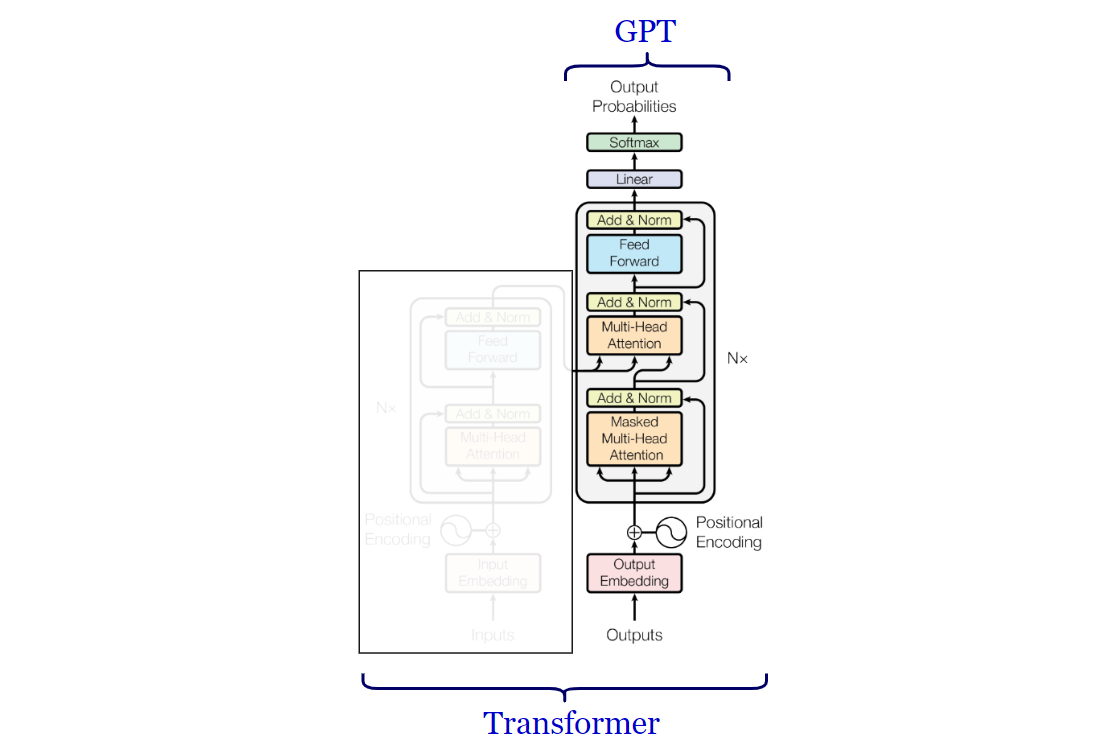

## Import Libraries

In [1]:
import torch

import torch.nn as nn
from torch.nn import functional as F

## Reading Dataset

In [2]:
torch.manual_seed(1337)

!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open('input.txt', 'r', encoding='utf-8') as f:
  text = f.read()

--2026-05-19 01:11:58--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt.4’

input.txt.4         100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-05-19 01:11:58 (40.6 MB/s) - ‘input.txt.4’ saved [1115394/1115394]



In [3]:
print("length of dataset in characters: ", len(text))

length of dataset in characters:  1115394


In [4]:
# let's look at the first 100 characters
print(text[:100])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You


# **Data preprocessing**
The code's initial segment pre-processes input text by tokenizing it into a word list, assigning a unique integer to each word, and creating fixed-length sequences through a sliding window method.

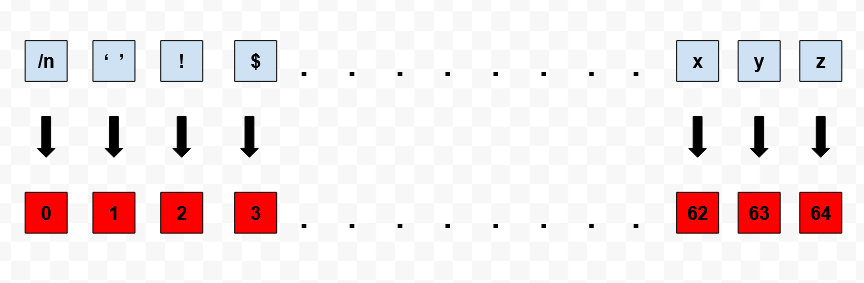

## Identifying unique characters that occur in a text

In [5]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(chars)
print(vocab_size)

['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
65


### Mapping human-comprehensible text symbols to computer-comprehensible numbers

In [6]:
#create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

print(encode("hii there"))
print(decode(encode("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


## Encoding input data

In [7]:
#let's now encode the entire text dataset and store it into a torch.Tensor
import torch # we use PyTorch: https://pytorch.org
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:100]) # the 100 characters we looked at earlier will to the GPT look like this

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])


### Splitting up the data into train and validation sets

In [8]:
# Let's now split up the data into train and validation sets
n = int(0.9*len(data)) # first 90% will be in train set, rest in val
train_data = data[:n]
val_data = data[n:]
block_size = 8 #which determines the input sequence size that the GPT model will process at a time
# train_data[:block_size+1]
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
  context = x[:t+1]
  target = y[t]
  print(f"when input is {context} the target: {target}")

when input is tensor([18]) the target: 47
when input is tensor([18, 47]) the target: 56
when input is tensor([18, 47, 56]) the target: 57
when input is tensor([18, 47, 56, 57]) the target: 58
when input is tensor([18, 47, 56, 57, 58]) the target: 1
when input is tensor([18, 47, 56, 57, 58,  1]) the target: 15
when input is tensor([18, 47, 56, 57, 58,  1, 15]) the target: 47
when input is tensor([18, 47, 56, 57, 58,  1, 15, 47]) the target: 58


## Generating batches of input and target data for training the GPT

In [10]:
torch.manual_seed(1337)

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# For the quick sanity print check
CHECK_BATCH_SIZE = 16
CHECK_BLOCK_SIZE = 8

def get_batch(split, b_size, blk_size):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - blk_size, (b_size,))
    x = torch.stack([data[i:i+blk_size] for i in ix])
    y = torch.stack([data[i+1:i+blk_size+1] for i in ix])
    return x.to(device), y.to(device)

# Call explicitly for the print test
xb, yb = get_batch('train', CHECK_BATCH_SIZE, CHECK_BLOCK_SIZE)
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

# Dynamically extract the actual batch and time dimensions of the tensor
B, T = xb.shape

for b in range(B): # iterates safely from 0 to 15
  for t in range(T): # iterates safely from 0 to 7
    context = xb[b, :t+1]
    target = yb[b,t]
    print(f"when input is {context.tolist()} the target: {target}")

inputs:
torch.Size([16, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54],
        [57, 43, 60, 43, 52,  1, 63, 43],
        [60, 43, 42,  8,  0, 25, 63,  1],
        [56, 42,  5, 57,  1, 57, 39, 49],
        [43, 57, 58, 63,  6,  1, 58, 46],
        [43,  1, 51, 39, 63,  1, 40, 43],
        [58, 46, 43,  1, 43, 39, 56, 57],
        [39, 58, 47, 53, 52, 12,  1, 37],
        [53, 56, 43,  1, 21,  1, 41, 39],
        [50, 39, 52, 63,  1, 47, 58, 57],
        [56, 53, 63,  1, 42, 47, 42,  1],
        [39, 51,  1, 39, 44, 56, 39, 47],
        [17, 24, 21, 38, 13, 14, 17, 32]], device='cuda:0')
targets:
torch.Size([16, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39],
        [43, 60, 43, 52,  1, 63, 43, 39],
        [43, 42,  8,  0, 25, 63,  1, 45],
 

# **Model configuration:**
This part of the code sets up the configuration parameters for the GPT model, specifying details such as the number of transformer layers, attention heads, hidden layer size, and vocabulary size.

## Hyperparameters:
- `batch_size`: Number of parallel sequences processed during training.
- `block_size`: Maximum context length for predictions.
- `max_iters`: Maximum training iterations for the GPT model.
- `eval_interval`: Interval for evaluating the model's performance during training.
- `learning_rate`: Learning rate for the optimizer during training.
- `device`: Device (CPU or GPU) for GPT model training.
- `eval_iters`: Evaluation and saving interval during training.
- `n_embd`: Number of embedding dimensions for the GPT model.
- `n_head`: Number of attention heads in the multi-head attention layer.
- `n_layer`: Number of layers in the GPT model.
- `dropout`: Dropout probability for regularization in the GPT model.



In [11]:
# Recommended Hyperparameters
batch_size = 64          # Process more sequences in parallel for stable gradients
block_size = 128         # Give it a larger window to remember character history
max_iters = 5000         # With a bigger batch size, you can reduce total iterations
eval_interval = 200
learning_rate = 5e-4     # Faster, aggressive convergence for small scratch models

eval_iters = 200
n_embd = 256
n_head = 8               # Changed from 16 -> 8 (Results in a better head_size of 32)
n_layer = 6
dropout = 0.2

## Calculating the average loss on the training and validation datasets using a pre-trained model

In [21]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split, batch_size, block_size)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

# Model Architecture

The following code segments define the GPT model architecture using PyTorch modules. The model comprises an embedding layer, a series of transformer layers, and a linear layer responsible for producing the probability distribution over the vocabulary, determining the next word in the sequence.


## Defining one head of the self-attention mechanism in a transformer model


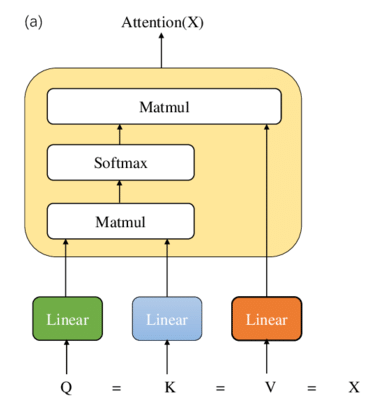

In [13]:
class Head(nn.Module):
#""" one head of self-attention """

  def __init__(self, head_size):
    super().__init__()
    self.key = nn.Linear(n_embd, head_size, bias=False)
    self.query = nn.Linear(n_embd, head_size, bias=False)
    self.value = nn.Linear(n_embd, head_size, bias=False)
    self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

    self.dropout = nn.Dropout(dropout)

  def forward(self, x):
    B,T,C = x.shape
    k = self.key(x) # (B,T,C)
    q = self.query(x) # (B,T,C)
    # compute attention scores ("affinities")
    wei = q @ k.transpose(-2,-1) * C**-0.5 # (B, T, C) @ (B, C, T) -> (B, T, T)
    wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf')) # (B, T, T)
    wei = F.softmax(wei, dim=-1) # (B, T, T)
    wei = self.dropout(wei)
    # perform the weighted aggregation of the values
    v = self.value(x) # (B,T,C)
    out = wei @ v # (B, T, T) @ (B, T, C) -> (B, T, C)
    return out

### Implementing the multi-head attention mechanism

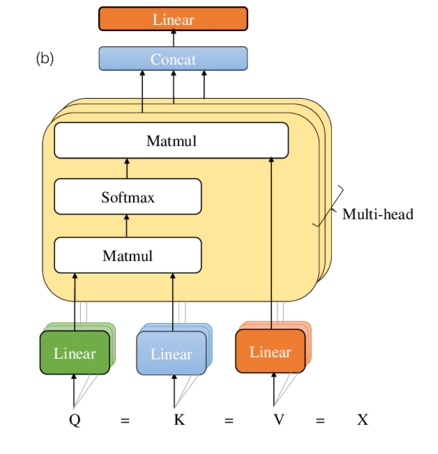

In [14]:
class MultiHeadAttention(nn.Module):
#""" multiple heads of self-attention in parallel """

  def __init__(self, num_heads, head_size):
    super().__init__()
    self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
    self.proj = nn.Linear(n_embd, n_embd)
    self.dropout = nn.Dropout(dropout)

  def forward(self, x):
    out = torch.cat([h(x) for h in self.heads], dim=-1)
    out = self.dropout(self.proj(out))
    return out

### Next we need to add the FeedFoward module

In [15]:
class FeedFoward(nn.Module):
#""" a simple linear layer followed by a non-linearity """

  def __init__(self, n_embd):
    super().__init__()
    self.net = nn.Sequential(
    nn.Linear(n_embd, 4 * n_embd),
    nn.ReLU(),
    nn.Linear(4 * n_embd, n_embd),
    nn.Dropout(dropout),
    )

  def forward(self, x):
    return self.net(x)

class Block(nn.Module):
#""" Transformer block: communication followed by computation """

  def __init__(self, n_embd, n_head):
  # n_embd: embedding dimension, n_head: the number of heads we'd like
    super().__init__()
    head_size = n_embd // n_head
    self.sa = MultiHeadAttention(n_head, head_size)
    self.ffwd = FeedFoward(n_embd)
    self.ln1 = nn.LayerNorm(n_embd)
    self.ln2 = nn.LayerNorm(n_embd)

  def forward(self, x):
    x = x + self.sa(self.ln1(x))
    x = x + self.ffwd(self.ln2(x))
    return x

### Model training and text generation

In [16]:
class BigramLanguageModel(nn.Module):

  def __init__(self):
    super().__init__()
    # each token directly reads off the logits for the next token from a lookup table
    self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
    self.position_embedding_table = nn.Embedding(block_size, n_embd)
    self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
    self.ln_f = nn.LayerNorm(n_embd) # final layer norm
    self.lm_head = nn.Linear(n_embd, vocab_size)

  def forward(self, idx, targets=None):
    B, T = idx.shape

    # idx and targets are both (B,T) tensor of integers
    tok_emb = self.token_embedding_table(idx) # (B,T,C)
    pos_emb = self.position_embedding_table(torch.arange(T, device=device)) # (T,C)
    x = tok_emb + pos_emb # (B,T,C)
    x = self.blocks(x) # (B,T,C)
    x = self.ln_f(x) # (B,T,C)
    logits = self.lm_head(x) # (B,T,vocab_size)

    if targets is None:
      loss = None
    else:
      B, T, C = logits.shape
      logits = logits.view(B*T, C)
      targets = targets.view(B*T)
      loss = F.cross_entropy(logits, targets)

    return logits, loss

  def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
    # idx is (B, T) array of indices in the current context
    for _ in range(max_new_tokens):
      # crop idx to the last block_size tokens
      idx_cond = idx[:, -block_size:]
      # get the predictions
      logits, loss = self(idx_cond)
      # focus only on the last time step
      logits = logits[:, -1, :] # becomes (B, C)

      # 1. Handle Temperature scaling
      if temperature != 1.0:
        logits = logits / temperature

      # 2. Handle Top-K filtering
      if top_k is not None:
        v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
        logits[logits < v[:, [-1]]] = -float('Inf')

      # apply softmax to get probabilities
      probs = F.softmax(logits, dim=-1) # (B, C)
      # sample from the distribution
      idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
      # append sampled index to the running sequence
      idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
    return idx

In [22]:
model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)


for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    # sample a batch of data
    xb, yb = get_batch('train', batch_size, block_size) # Uses 64 and 128

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()


4.800577 M parameters
step 0: train loss 4.3655, val loss 4.3665
step 200: train loss 2.3729, val loss 2.3863
step 400: train loss 2.0466, val loss 2.1030
step 600: train loss 1.8267, val loss 1.9493
step 800: train loss 1.6798, val loss 1.8475
step 1000: train loss 1.5895, val loss 1.7703
step 1200: train loss 1.5271, val loss 1.7105
step 1400: train loss 1.4833, val loss 1.6818
step 1600: train loss 1.4406, val loss 1.6407
step 1800: train loss 1.4114, val loss 1.6193
step 2000: train loss 1.3834, val loss 1.5934
step 2200: train loss 1.3648, val loss 1.5840
step 2400: train loss 1.3458, val loss 1.5653
step 2600: train loss 1.3232, val loss 1.5444
step 2800: train loss 1.3100, val loss 1.5394
step 3000: train loss 1.2970, val loss 1.5396
step 3200: train loss 1.2844, val loss 1.5334
step 3400: train loss 1.2701, val loss 1.5215
step 3600: train loss 1.2608, val loss 1.5200
step 3800: train loss 1.2537, val loss 1.5155
step 4000: train loss 1.2400, val loss 1.5179
step 4200: train lo

In [23]:
# generate from the model
context = torch.full((1, 1), 39, dtype=torch.long, device=device)

# Try setting temperature to 0.7 and constraining choices to the top 8 characters
print(decode(m.generate(context, max_new_tokens=200, temperature=0.7, top_k=8)[0].tolist()))

and fiend his part to the people,
And by the triumph of the shame be disposition,
As I am courted of a crown to a heavy will
As with the bear for thy prison. How how since my lawful
Of all one all to h


In [24]:
# Try a couple of variations to see how the model behaves!

# Option A: A balanced, safe approach
print(decode(m.generate(context, max_new_tokens=500, temperature=0.7, top_k=10)[0].tolist()))

print("-" * 40)

# Option B: A slightly more creative/unpredictable approach
print(decode(m.generate(context, max_new_tokens=500, temperature=0.85, top_k=15)[0].tolist()))

aved forgiful said, and this shore,
Which thought though the business of mends;
But thou mayst me there at him in blastard,
And safe his foul haste so for with heavy the strain:
I should there it is so; and some seeing we one thing
To make me an all sore become to a courself.

KING RICHARD II:
O heaven!

DUKE OF AUMERLE:
I change thee, that we deserve the traitor's daughter;
And be for the statue off the people and service,
On the earies of the bear's the mate.

KING HENRY VI:

Nurse;
And I canno
----------------------------------------
and to him made
Made his destrance for thy entreatiness.
My mother!
And let you, lie an exta morning with again,
Who walk thy tongue of living lie our throats
And notry i' the weak not: no stone of worth
To grant the word of our sweet the sword sents,
It is seen at our trice, and mild and fear.

ROMEO:
I will fain does to thee that abhorit.

WARWICK:
But if the eyes in hangmen shall have dead.

KING HENRY VI:
Madam, what fourth I seed you hear men hath 